In [1]:
# ==============================================================================
# CELL 0: ENVIRONMENT SETUP & DATASET DOWNLOAD
# ==============================================================================
!pip install gdown timm -q

import os, zipfile
import gdown
from pathlib import Path

GDRIVE_FILE_ID = "1SSZxRtmOY9T4W8VwXPJK8WPwd4sB4tpz"
ZIP_PATH = "/kaggle/working/Final_preprocessed_V3.zip"
DATASET_DIR = Path("/kaggle/working/Final_preprocessed_V3")

if not DATASET_DIR.exists():
    print("🔄 Downloading Final_preprocessed_V3.zip from Google Drive...")
    gdown.download(f"https://drive.google.com/uc?id={GDRIVE_FILE_ID}", ZIP_PATH, quiet=False)
    
    print("📦 Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall("/kaggle/working")
    
    if os.path.exists(ZIP_PATH):
        os.remove(ZIP_PATH)
        print("🗑 Removed zip to preserve disk space.")
    print(f"✅ Dataset ready at {DATASET_DIR}")
else:
    print(f"✅ Dataset already exists at {DATASET_DIR}")

🔄 Downloading Final_preprocessed_V3.zip from Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1SSZxRtmOY9T4W8VwXPJK8WPwd4sB4tpz
From (redirected): https://drive.google.com/uc?id=1SSZxRtmOY9T4W8VwXPJK8WPwd4sB4tpz&confirm=t&uuid=b68b83bb-b2d9-4dd8-992a-496f43a2705e
To: /kaggle/working/Final_preprocessed_V3.zip
100%|██████████| 696M/696M [00:04<00:00, 174MB/s] 


📦 Extracting dataset...
🗑 Removed zip to preserve disk space.
✅ Dataset ready at /kaggle/working/Final_preprocessed_V3


In [2]:
# ==============================================================================
# CELL 1: BUILD MASTER DATASET CSV
# ==============================================================================
import os, re
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

ROOT_DIR = Path("/kaggle/working/Final_preprocessed_V3")
CSV_OUT = "/kaggle/working/dataset_3_classes.csv"

patient_dirs = []
for category in ["normal", "disease"]:
    cat_dir = ROOT_DIR / category
    if cat_dir.exists():
        for entry in sorted(cat_dir.iterdir()):
            if entry.is_dir() and (entry / "images").exists():
                patient_dirs.append(entry)

print(f"🔍 Discovered {len(patient_dirs)} patient directories")

CLASS_NAMES = ['Normal Study', 'Infarct / Ischemia', 'Cerebral / Cortical Atrophy']
COL_NAMES = ['Normal_Study', 'Infarct_Ischemia', 'Cerebral_Atrophy']

records = []
for p_dir in tqdm(patient_dirs, desc="Parsing Patient Data"):
    patient_id = p_dir.name
    img_folder = p_dir / "images"
    csv_folder = p_dir / "csv"
    
    slice_images = sorted(list(img_folder.glob("*.png")) + list(img_folder.glob("*.jpg")))
    slice_count = len(slice_images)
    
    normal, infarct, atrophy = 0, 0, 0
    if csv_folder.exists():
        pat_csvs = list(csv_folder.glob("*.csv"))
        if pat_csvs:
            try:
                p_df = pd.read_csv(pat_csvs[0])
                if 'class' in p_df.columns and 'label' in p_df.columns:
                    label_map = dict(zip(p_df['class'], p_df['label']))
                    normal  = int(label_map.get('Normal Study', 0))
                    infarct = int(label_map.get('Infarct / Ischemia', 0))
                    atrophy = int(label_map.get('Cerebral / Cortical Atrophy', 0))
            except Exception as e:
                pass
                
    records.append({
        'patient_id': patient_id,
        'category': p_dir.parent.name,
        'folder_path': str(p_dir),
        'image_folder': str(img_folder),
        'slice_count': slice_count,
        'Normal_Study': normal,
        'Infarct_Ischemia': infarct,
        'Cerebral_Atrophy': atrophy,
    })

df_master = pd.DataFrame(records)
df_master.to_csv(CSV_OUT, index=False)
print(f"✅ Master CSV saved: {CSV_OUT} ({len(df_master)} patients)")

🔍 Discovered 1819 patient directories


Parsing Patient Data:   0%|          | 0/1819 [00:00<?, ?it/s]

✅ Master CSV saved: /kaggle/working/dataset_3_classes.csv (1819 patients)


In [9]:
%%writefile /kaggle/working/dataset_pipeline.py
import time, copy, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMG_SIZE = 224
NUM_SLICES = 14

class VolumetricBrainCTDataset(Dataset):
    def __init__(self, dataframe, classes, is_training=False, label_smoothing=0.05):
        self.df = dataframe.reset_index(drop=True)
        self.classes = classes
        self.is_training = is_training
        self.label_smoothing = label_smoothing
        self.normalize = transforms.Normalize(mean=[0.485], std=[0.229])
    
    def __len__(self):
        return len(self.df)
    
    def _sample_affine(self):
        angle = float(np.random.uniform(-10, 10))
        scale = float(np.random.uniform(0.92, 1.08))
        translate = (float(np.random.uniform(-8, 8) / IMG_SIZE), float(np.random.uniform(-8, 8) / IMG_SIZE))
        contrast = float(np.random.uniform(0.90, 1.10))
        brightness = float(np.random.uniform(-0.05, 0.05))
        return angle, scale, translate, contrast, brightness

    def _apply_affine(self, img_t, angle, scale, translate, contrast, brightness):
        theta = torch.zeros(1, 2, 3)
        cos_a = np.cos(np.radians(angle)) * scale
        sin_a = np.sin(np.radians(angle)) * scale
        theta[0, 0, 0] = cos_a
        theta[0, 0, 1] = -sin_a
        theta[0, 0, 2] = translate[0]
        theta[0, 1, 0] = sin_a
        theta[0, 1, 1] = cos_a
        theta[0, 1, 2] = translate[1]
        grid = F.affine_grid(theta, img_t.unsqueeze(0).size(), align_corners=False)
        warped = F.grid_sample(img_t.unsqueeze(0), grid, align_corners=False, mode='bilinear', padding_mode='zeros').squeeze(0)
        return (warped * contrast + brightness).clamp(0, 1)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_folder = Path(row['image_folder'])
        slice_paths = sorted(list(img_folder.glob("*.png")) + list(img_folder.glob("*.jpg")))[:NUM_SLICES]
        while len(slice_paths) < NUM_SLICES:
            slice_paths.append(slice_paths[-1])
        if self.is_training:
            aug_params = self._sample_affine()
        slices = []
        for sp in slice_paths:
            img = Image.open(sp).convert('L').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            img_t = transforms.ToTensor()(img)
            if self.is_training:
                img_t = self._apply_affine(img_t, *aug_params)
            slices.append(self.normalize(img_t))
        volume = torch.stack(slices, dim=0)
        labels = torch.tensor([row[c] for c in self.classes], dtype=torch.float32)
        if self.is_training and self.label_smoothing > 0:
            labels = labels * (1.0 - self.label_smoothing) + 0.5 * self.label_smoothing
        return volume, labels

Writing /kaggle/working/dataset_pipeline.py


In [15]:
# ==============================================================================
# CELL 2: SPLITS & DATALOADERS SETUP (BATCH_SIZE = 4 FOR VRAM SAFETY)
# ==============================================================================
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from dataset_pipeline import VolumetricBrainCTDataset

warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️ Device: {device} ({torch.cuda.get_device_name(0) if device.type=='cuda' else 'CPU'})")

CLASSES = ['Normal_Study', 'Infarct_Ischemia', 'Cerebral_Atrophy']
CLASS_NAMES = ['Normal Study', 'Infarct / Ischemia', 'Cerebral Atrophy']
NUM_CLASSES = 3
NUM_SLICES = 14
IMG_SIZE = 224
BATCH_SIZE = 4  # Reduced from 8 to 4 to prevent unfreeze OOM

df = pd.read_csv("/kaggle/working/dataset_3_classes.csv")
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, random_state=SEED)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)
print(f"📊 Splits: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

train_loader = DataLoader(VolumetricBrainCTDataset(train_df, CLASSES, is_training=True),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(VolumetricBrainCTDataset(val_df, CLASSES, is_training=False),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(VolumetricBrainCTDataset(test_df, CLASSES, is_training=False),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print("✅ DataLoaders prepared with BATCH_SIZE = 4")

🖥️ Device: cuda (Tesla T4)
📊 Splits: Train=1273, Val=273, Test=273
✅ DataLoaders prepared with BATCH_SIZE = 4


In [18]:
import gc, torch
gc.collect()
torch.cuda.empty_cache()
print(f"✅ VRAM Cleared! Free memory: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB / {torch.cuda.mem_get_info()[1]/1e9:.2f} GB")

✅ VRAM Cleared! Free memory: 13.80 GB / 15.64 GB


In [19]:
# ==============================================================================
# CELL 3: MEMORY-EFFICIENT EFFICIENTNET VOLUMETRIC ARCHITECTURE
# ==============================================================================
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F

MODEL_NAME = 'efficientnet_b3'  # Choose 'efficientnet_b3' or 'efficientnet_b4'

class SliceAttention(nn.Module):
    def __init__(self, feature_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(feature_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        # x: (B, S, D)
        scores = self.net(x)
        weights = F.softmax(scores, dim=1)
        out = (x * weights).sum(dim=1)
        return out, weights.squeeze(-1)

class EfficientNetBrainCTClassifier(nn.Module):
    def __init__(self, model_name='efficientnet_b3', num_classes=3, pretrained=True, dropout_rate=0.3):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, in_chans=1, num_classes=0)
        self.feature_dim = self.backbone.num_features
        self.slice_attention = SliceAttention(self.feature_dim)
        
        self.classifier = nn.Sequential(
            nn.LayerNorm(self.feature_dim),
            nn.Dropout(dropout_rate),
            nn.Linear(self.feature_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate * 0.5),
            nn.Linear(256, num_classes)
        )
        self.slice_drop_prob = 0.05

    def forward(self, volume):
        B, S, C, H, W = volume.shape
        # Memory-safe: iterate slice-by-slice (processes only B images at a time, 14x less VRAM!)
        slice_feats = []
        for s in range(S):
            feat = self.backbone(volume[:, s]) # (B, feature_dim)
            slice_feats.append(feat)
        slice_feats = torch.stack(slice_feats, dim=1) # (B, S, feature_dim)
        
        if self.training and np.random.random() < self.slice_drop_prob:
            drop_idx = np.random.randint(0, S)
            slice_feats[:, drop_idx] = 0.0
            
        patient_feat, attn_weights = self.slice_attention(slice_feats)
        logits = self.classifier(patient_feat)
        return logits, attn_weights

model = EfficientNetBrainCTClassifier(model_name=MODEL_NAME, num_classes=NUM_CLASSES, pretrained=True).to(device)
print(f"✅ {MODEL_NAME.upper()} Initialized (Memory-Safe Slice-by-Slice Mode)")
print(f"   Backbone Feature Dim: {model.feature_dim}")
print(f"   Total Parameters:     {sum(p.numel() for p in model.parameters()):,}")

✅ EFFICIENTNET_B3 Initialized (Memory-Safe Slice-by-Slice Mode)
   Backbone Feature Dim: 1536
   Total Parameters:     11,289,692


In [20]:
# ==============================================================================
# CELL 4: FP32 TRAINING WITH GRADIENT ACCUMULATION (EFFECTIVE BATCH = 8)
# ==============================================================================
from sklearn.metrics import roc_auc_score

EPOCHS = 16
FREEZE_EPOCHS = 3
PATIENCE = 5
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0
ACCUM_STEPS = 2  # 4 x 2 = effective batch size of 8

# Damped Positive Class Weights (sqrt ratio)
pos_counts = train_df[CLASSES].sum().values
neg_counts = len(train_df) - pos_counts
pos_weights = torch.tensor(np.sqrt(neg_counts / np.maximum(pos_counts, 1)), dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)

# Stage 1: Freeze Backbone
for param in model.backbone.parameters():
    param.requires_grad = False
model.backbone.eval()

optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

best_val_auc = 0.0
best_epoch = 0
best_model_state = None
patience_counter = 0

history = {'train_loss': [], 'val_loss': [], 'val_macro_auc': []}
exp_dir = Path(f"/kaggle/working/experiments/{MODEL_NAME}_BrainCT")
exp_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = exp_dir / f"best_{MODEL_NAME}_model.pth"

torch.cuda.empty_cache()
print(f"\n🏁 Commencing Training: {MODEL_NAME.upper()} (Batch Size: 4, Accum: 2 -> Eff. Batch: 8)")

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    
    # Stage 2: Unfreeze Backbone at Epoch 4
    if epoch == FREEZE_EPOCHS + 1:
        print(f"\n🔓 Unfreezing {MODEL_NAME} backbone with differential LR...")
        torch.cuda.empty_cache()
        for param in model.backbone.parameters():
            param.requires_grad = True
        optimizer = torch.optim.AdamW([
            {'params': model.backbone.parameters(),        'lr': 1e-5},
            {'params': model.slice_attention.parameters(), 'lr': 8e-5},
            {'params': model.classifier.parameters(),      'lr': 8e-5},
        ], weight_decay=WEIGHT_DECAY)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=(EPOCHS - FREEZE_EPOCHS))

    # Train
    model.train()
    if epoch <= FREEZE_EPOCHS:
        model.backbone.eval()
        
    running_loss = 0.0
    optimizer.zero_grad()
    
    for step, (volumes, labels) in enumerate(train_loader):
        volumes = volumes.to(device, non_blocking=True)
        labels  = labels.to(device, non_blocking=True)
        
        logits, _ = model(volumes)
        loss = criterion(logits, labels) / ACCUM_STEPS
        
        if torch.isnan(loss) or torch.isinf(loss):
            continue
            
        loss.backward()
        
        # Step optimizer every ACCUM_STEPS iterations
        if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(train_loader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            optimizer.zero_grad()
            
        running_loss += loss.item() * ACCUM_STEPS
        
    train_loss = running_loss / max(len(train_loader), 1)
    
    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_probs, val_labels = [], []
    with torch.no_grad():
        for volumes, labels in val_loader:
            volumes = volumes.to(device, non_blocking=True)
            labels  = labels.to(device, non_blocking=True)
            
            logits, _ = model(volumes)
            loss = criterion(logits, labels)
            
            val_loss_sum += loss.item()
            probs = torch.sigmoid(logits).cpu().numpy()
            val_probs.append(probs)
            val_labels.append(labels.cpu().numpy())
            
    val_loss = val_loss_sum / max(len(val_loader), 1)
    val_probs = np.concatenate(val_probs, axis=0)
    val_labels = np.concatenate(val_labels, axis=0)
    val_probs = np.nan_to_num(val_probs, nan=0.5, posinf=1.0, neginf=0.0)
    
    per_class_auc = []
    for c in range(NUM_CLASSES):
        try:
            auc = roc_auc_score(val_labels[:, c], val_probs[:, c])
        except ValueError:
            auc = 0.5
        per_class_auc.append(auc)
        
    val_macro_auc = float(np.mean(per_class_auc))
    scheduler.step()
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_macro_auc'].append(val_macro_auc)
    
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro-AUC: {val_macro_auc:.4f} | Time: {time.time()-epoch_start:.0f}s")
    
    if val_macro_auc > best_val_auc:
        best_val_auc = val_macro_auc
        best_epoch = epoch
        patience_counter = 0
        best_model_state = copy.deepcopy(model.state_dict())
        torch.save(best_model_state, checkpoint_path)
        print(f"  ⭐ Best Model Saved! (AUC: {best_val_auc:.4f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n🛑 Early stopping triggered at Epoch {epoch}")
            break

print(f"\n✅ Training Completed. Best Epoch: {best_epoch} with Val Macro-AUC: {best_val_auc:.4f}")


🏁 Commencing Training: EFFICIENTNET_B3 (Batch Size: 4, Accum: 2 -> Eff. Batch: 8)
Epoch 01/16 | Train Loss: 0.5235 | Val Loss: 0.5120 | Val Macro-AUC: 0.8493 | Time: 77s
  ⭐ Best Model Saved! (AUC: 0.8493)
Epoch 02/16 | Train Loss: 0.4627 | Val Loss: 0.5058 | Val Macro-AUC: 0.8550 | Time: 75s
  ⭐ Best Model Saved! (AUC: 0.8550)
Epoch 03/16 | Train Loss: 0.4419 | Val Loss: 0.5016 | Val Macro-AUC: 0.8614 | Time: 75s
  ⭐ Best Model Saved! (AUC: 0.8614)

🔓 Unfreezing efficientnet_b3 backbone with differential LR...
Epoch 04/16 | Train Loss: 0.5639 | Val Loss: 0.5970 | Val Macro-AUC: 0.8096 | Time: 275s
Epoch 05/16 | Train Loss: 0.4895 | Val Loss: 0.5248 | Val Macro-AUC: 0.8422 | Time: 275s
Epoch 06/16 | Train Loss: 0.4687 | Val Loss: 0.6697 | Val Macro-AUC: 0.8003 | Time: 275s
Epoch 07/16 | Train Loss: 0.4504 | Val Loss: 0.5292 | Val Macro-AUC: 0.8586 | Time: 275s
Epoch 08/16 | Train Loss: 0.4556 | Val Loss: 0.5833 | Val Macro-AUC: 0.8241 | Time: 274s

🛑 Early stopping triggered at Epoch 

In [21]:
# ==============================================================================
# CELL 5: VALIDATION MAX-F1 THRESHOLDING & TEST METRICS EVALUATION
# ==============================================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

model.load_state_dict(best_model_state)
model.eval()

def run_inference(loader):
    probs, labels, attns = [], [], []
    with torch.no_grad():
        for volumes, labs in loader:
            volumes = volumes.to(device)
            with torch.amp.autocast('cuda'):
                logits, attn = model(volumes)
            probs.append(torch.sigmoid(logits).cpu().numpy())
            labels.append(labs.numpy())
            attns.append(attn.cpu().numpy())
    return np.concatenate(probs), np.concatenate(labels), np.concatenate(attns)

print("🔍 Running Validation & Test Inference...")
val_probs, val_labels, _ = run_inference(val_loader)
test_probs, test_labels, test_attns = run_inference(test_loader)

# Step 1: Calibrate Max-F1 Thresholds on Validation Cohort Only
optimal_thresholds = []
for c in range(NUM_CLASSES):
    y_true_v = val_labels[:, c].astype(int)
    y_prob_v = val_probs[:, c]
    best_f1, best_th = -1.0, 0.50
    for th in np.linspace(0.10, 0.90, 81):
        f1 = f1_score(y_true_v, (y_prob_v >= th).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_th = th
    optimal_thresholds.append(best_th)

# Step 2: Calculate Test Metrics
test_rows = []
for c in range(NUM_CLASSES):
    th = optimal_thresholds[c]
    preds = (test_probs[:, c] >= th).astype(int)
    gt = test_labels[:, c].astype(int)
    
    tn, fp, fn, tp = confusion_matrix(gt, preds, labels=[0, 1]).ravel()
    acc = accuracy_score(gt, preds)
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    prec = tp / max(tp + fp, 1)
    f1 = 2 * prec * sens / max(prec + sens, 1e-8)
    auc_score = roc_auc_score(gt, test_probs[:, c])
    
    test_rows.append({
        'Class': CLASS_NAMES[c],
        'Threshold': th,
        'Accuracy': acc,
        'Sensitivity (Recall)': sens,
        'Specificity': spec,
        'Precision': prec,
        'F1-Score': f1,
        'ROC-AUC': auc_score,
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn
    })

# Macro Average
macro_row = {
    'Class': 'MACRO AVERAGE',
    'Threshold': 'Adaptive',
    'Accuracy': np.mean([r['Accuracy'] for r in test_rows]),
    'Sensitivity (Recall)': np.mean([r['Sensitivity (Recall)'] for r in test_rows]),
    'Specificity': np.mean([r['Specificity'] for r in test_rows]),
    'Precision': np.mean([r['Precision'] for r in test_rows]),
    'F1-Score': np.mean([r['F1-Score'] for r in test_rows]),
    'ROC-AUC': np.mean([r['ROC-AUC'] for r in test_rows]),
    'TP': sum([r['TP'] for r in test_rows]),
    'TN': sum([r['TN'] for r in test_rows]),
    'FP': sum([r['FP'] for r in test_rows]),
    'FN': sum([r['FN'] for r in test_rows])
}
test_rows.append(macro_row)
df_metrics = pd.DataFrame(test_rows)

print("\n" + "="*80)
print(f"  📊 {MODEL_NAME.upper()} TEST SET PERFORMANCE (N = {len(test_labels)})")
print("="*80)
disp_cols = ['Class', 'Threshold', 'Accuracy', 'Sensitivity (Recall)', 'Specificity', 'Precision', 'F1-Score', 'ROC-AUC']
print(df_metrics[disp_cols].to_string(index=False))
df_metrics.to_csv(exp_dir / "test_metrics.csv", index=False)

🔍 Running Validation & Test Inference...

  📊 EFFICIENTNET_B3 TEST SET PERFORMANCE (N = 273)
             Class Threshold  Accuracy  Sensitivity (Recall)  Specificity  Precision  F1-Score  ROC-AUC
      Normal Study      0.58  0.831502              0.858896     0.790909   0.858896  0.858896 0.910011
Infarct / Ischemia       0.3  0.816850              0.826531     0.811429   0.710526  0.764151 0.892536
  Cerebral Atrophy      0.49  0.868132              0.858824     0.872340   0.752577  0.802198 0.929443
     MACRO AVERAGE  Adaptive  0.838828              0.848083     0.824893   0.774000  0.808415 0.910664


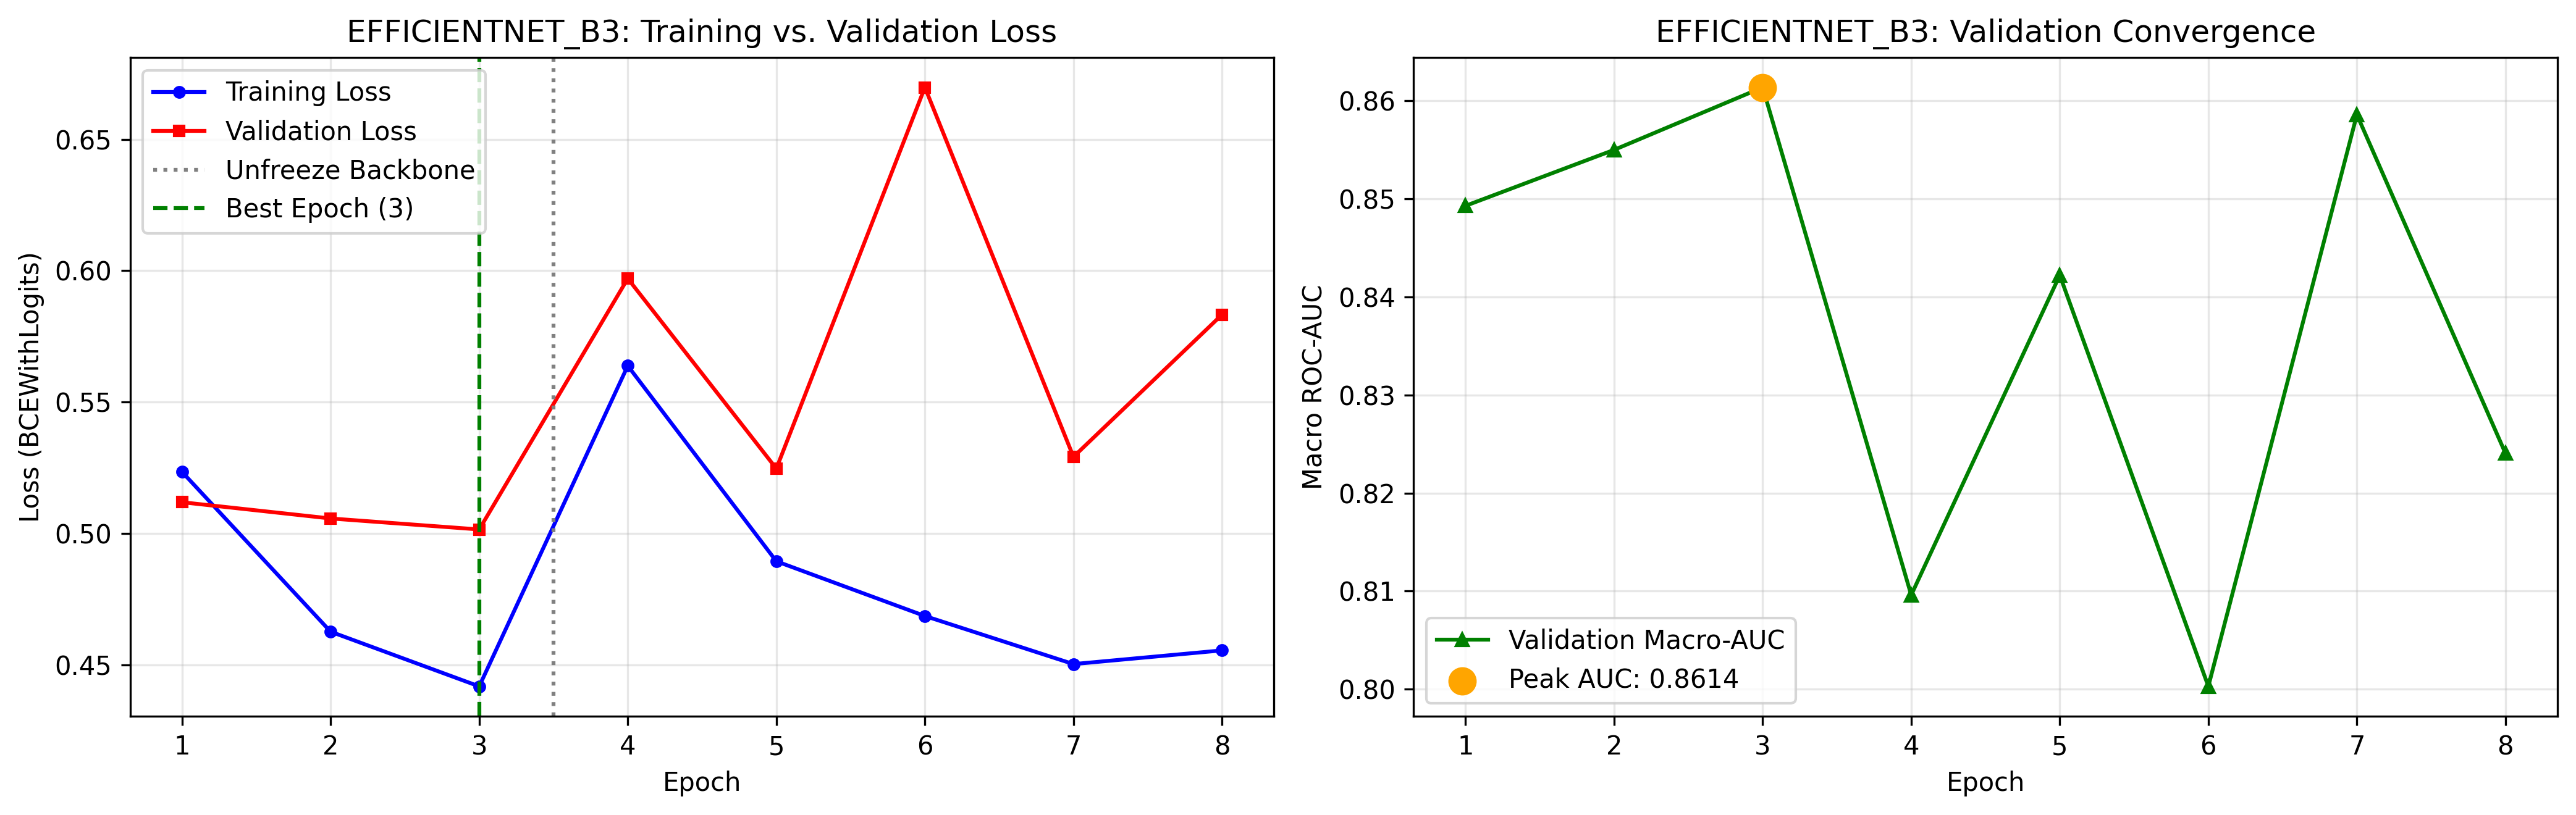

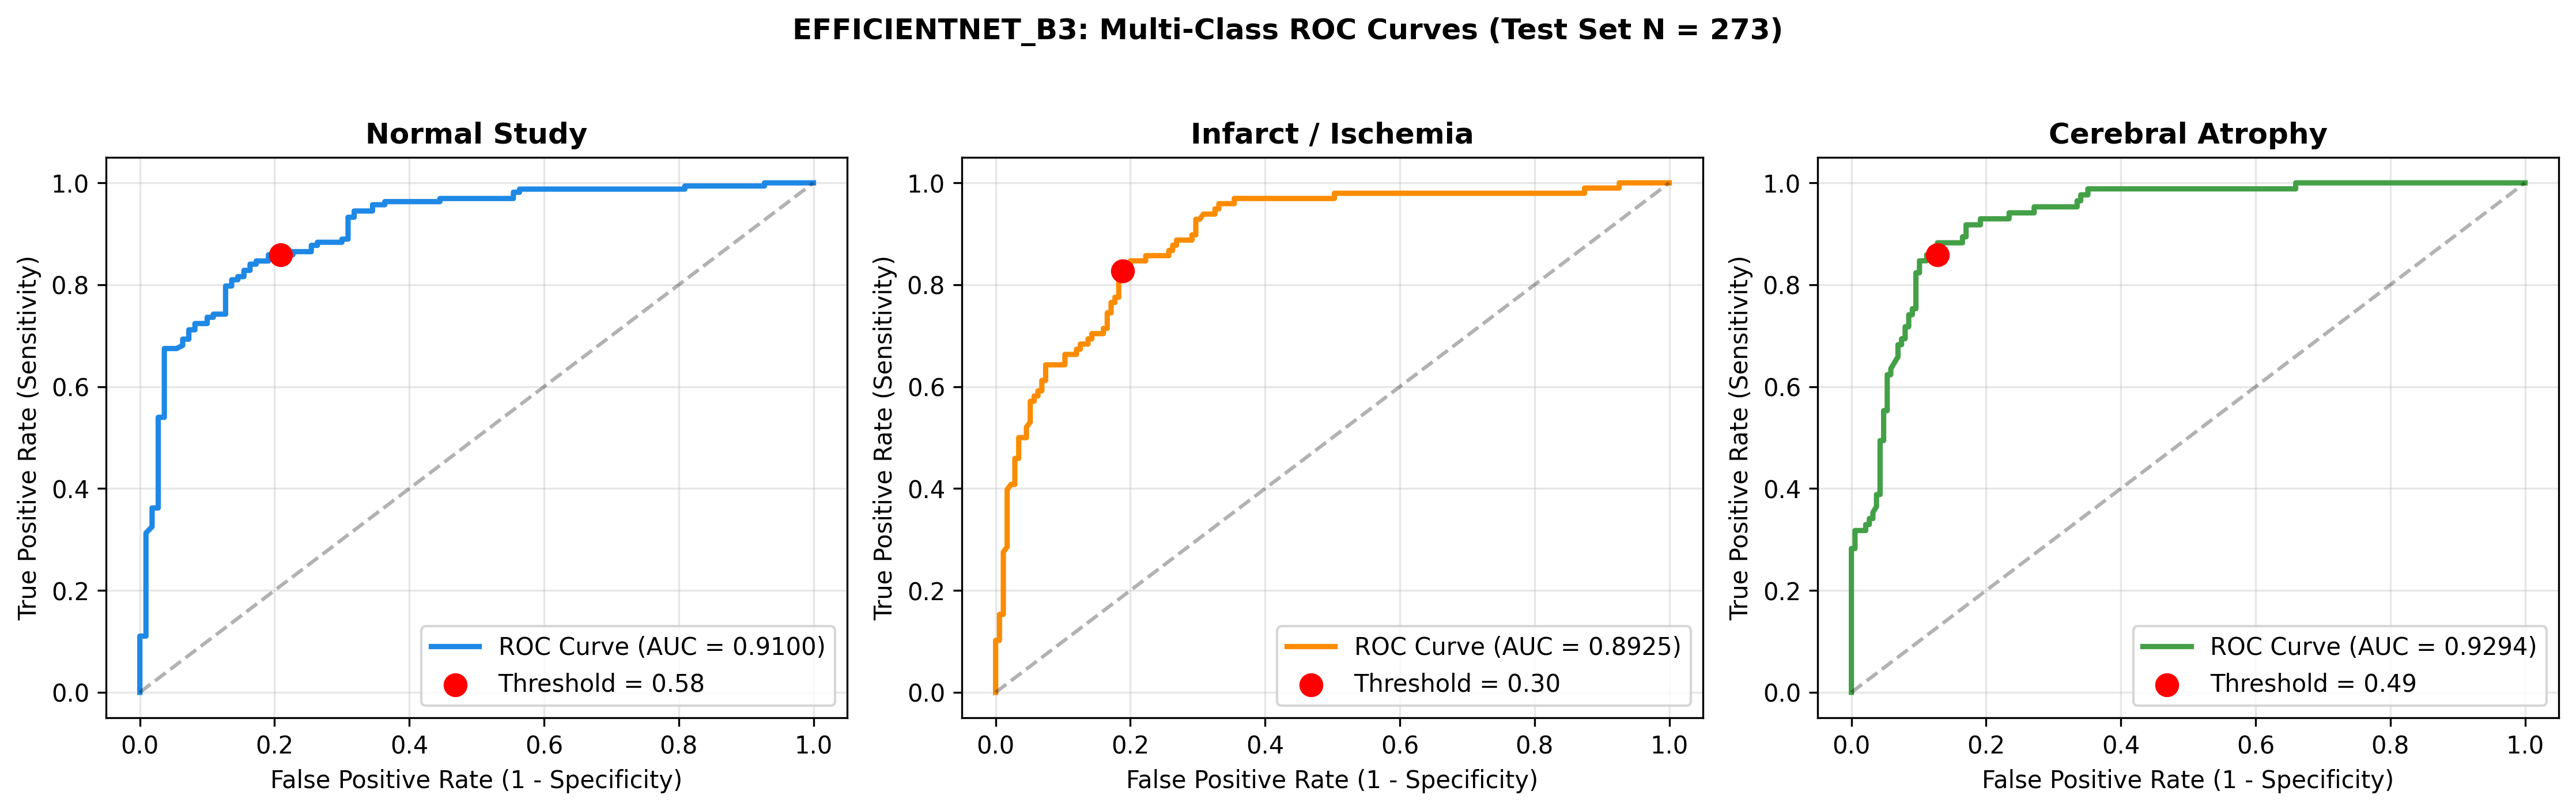

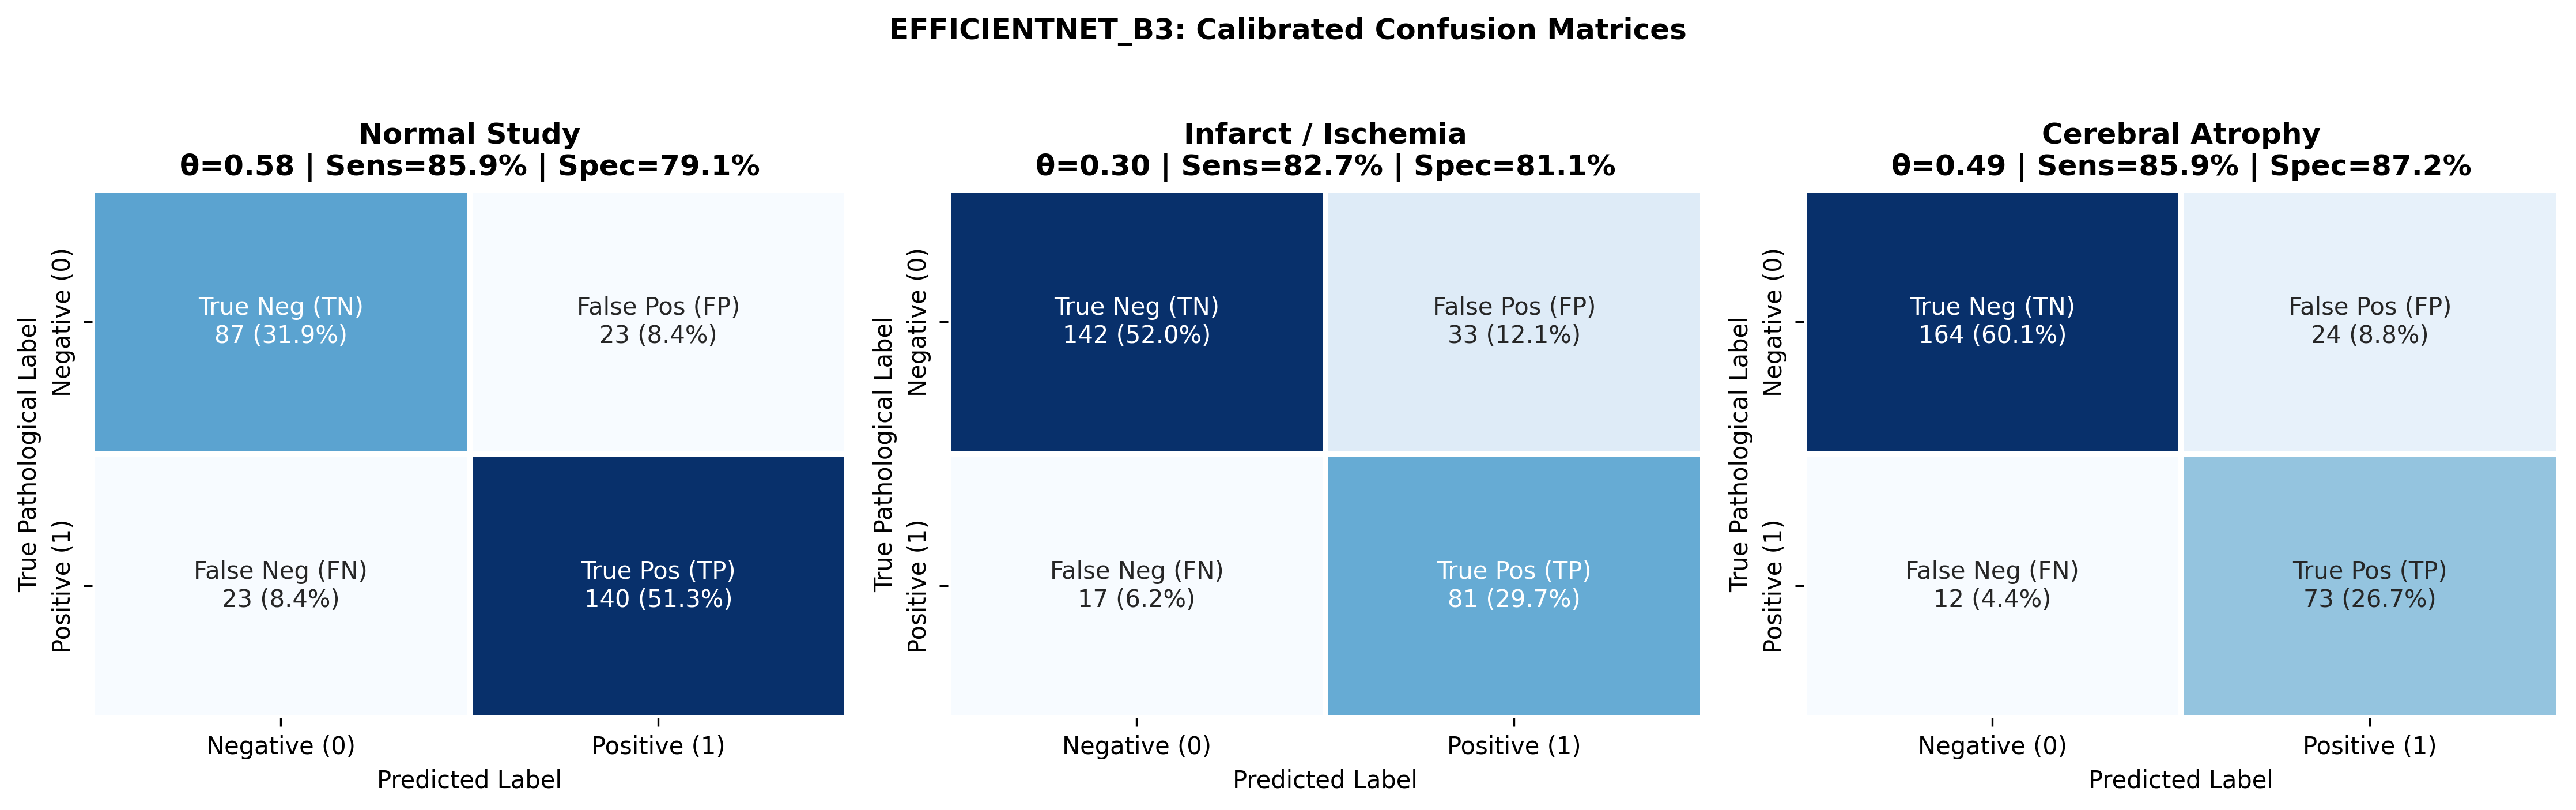

✅ All publication figures saved to: /kaggle/working/experiments/efficientnet_b3_BrainCT


In [22]:
# ==============================================================================
# CELL 6: PUBLICATION FIGURES (300 DPI)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

palette = ['#1E88E5', '#FB8C00', '#43A047']

# ── Fig 1: Training vs. Validation Loss and ROC-AUC ───────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), dpi=300)
epochs_range = range(1, len(history['train_loss']) + 1)

ax1.plot(epochs_range, history['train_loss'], 'b-o', markersize=4, label='Training Loss')
ax1.plot(epochs_range, history['val_loss'], 'r-s', markersize=4, label='Validation Loss')
ax1.axvline(x=FREEZE_EPOCHS + 0.5, color='gray', linestyle=':', label='Unfreeze Backbone')
ax1.axvline(x=best_epoch, color='green', linestyle='--', label=f'Best Epoch ({best_epoch})')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss (BCEWithLogits)')
ax1.set_title(f'{MODEL_NAME.upper()}: Training vs. Validation Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_range, history['val_macro_auc'], 'g-^', markersize=5, label='Validation Macro-AUC')
ax2.scatter([best_epoch], [best_val_auc], color='orange', s=100, zorder=5, label=f'Peak AUC: {best_val_auc:.4f}')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Macro ROC-AUC')
ax2.set_title(f'{MODEL_NAME.upper()}: Validation Convergence')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(exp_dir / f"{MODEL_NAME}_loss_curves.png", bbox_inches='tight')
plt.show()

# ── Fig 2: Per-Class ROC Curves ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=300)
for c in range(3):
    fpr, tpr, _ = roc_curve(test_labels[:, c], test_probs[:, c])
    auc_val = roc_auc_score(test_labels[:, c], test_probs[:, c])
    
    axes[c].plot(fpr, tpr, color=palette[c], lw=2.2, label=f'ROC Curve (AUC = {auc_val:.4f})')
    axes[c].plot([0, 1], [0, 1], 'k--', alpha=0.3)
    
    # Mark optimal threshold
    th = optimal_thresholds[c]
    preds = (test_probs[:, c] >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(test_labels[:, c], preds, labels=[0, 1]).ravel()
    axes[c].scatter([fp / (fp + tn)], [tp / (tp + fn)], color='red', s=80, zorder=5, label=f'Threshold = {th:.2f}')
    
    axes[c].set_title(CLASS_NAMES[c], fontweight='bold')
    axes[c].set_xlabel('False Positive Rate (1 - Specificity)')
    axes[c].set_ylabel('True Positive Rate (Sensitivity)')
    axes[c].legend(loc='lower right')
    axes[c].grid(True, alpha=0.3)

plt.suptitle(f"{MODEL_NAME.upper()}: Multi-Class ROC Curves (Test Set N = {len(test_labels)})", y=1.03, fontweight='bold')
plt.tight_layout()
plt.savefig(exp_dir / f"{MODEL_NAME}_roc_curves.png", bbox_inches='tight')
plt.show()

# ── Fig 3: Calibrated 2x2 Confusion Matrices ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=300)
cmap = sns.color_palette("Blues", as_cmap=True)

for c in range(3):
    th = optimal_thresholds[c]
    preds = (test_probs[:, c] >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(test_labels[:, c], preds, labels=[0, 1]).ravel()
    tot = tn + fp + fn + tp
    cm = np.array([[tn, fp], [fn, tp]])
    
    annot = np.array([
        [f"True Neg (TN)\n{tn} ({tn/tot*100:.1f}%)", f"False Pos (FP)\n{fp} ({fp/tot*100:.1f}%)"],
        [f"False Neg (FN)\n{fn} ({fn/tot*100:.1f}%)", f"True Pos (TP)\n{tp} ({tp/tot*100:.1f}%)"]
    ])
    
    sns.heatmap(cm, annot=annot, fmt='', cmap=cmap, cbar=False, ax=axes[c],
                xticklabels=['Negative (0)', 'Positive (1)'],
                yticklabels=['Negative (0)', 'Positive (1)'],
                linewidths=2, linecolor='white')
    axes[c].set_title(f"{CLASS_NAMES[c]}\nθ={th:.2f} | Sens={tp/max(tp+fn,1):.1%} | Spec={tn/max(tn+fp,1):.1%}", fontweight='bold')
    axes[c].set_xlabel('Predicted Label')
    axes[c].set_ylabel('True Pathological Label')

plt.suptitle(f"{MODEL_NAME.upper()}: Calibrated Confusion Matrices", y=1.03, fontweight='bold')
plt.tight_layout()
plt.savefig(exp_dir / f"{MODEL_NAME}_confusion_matrices.png", bbox_inches='tight')
plt.show()
print(f"✅ All publication figures saved to: {exp_dir}")